# 01 · Exploratory data analysis

What is in the data, and what does it mean for the models? Each section asks a question, shows the raw data first and ends with key findings.

Needs:
- the Kaggle data in `raw_data_dir` (see `configs/paths.yaml`);
- the DICOM header table from `scripts/extract_dicom_headers.py`. Reading the headers of ~874K files takes a while, so a script does it once and this notebook reads the result.

In [1]:
import os
from concurrent.futures import ThreadPoolExecutor

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydicom

from ich.paths import load_paths

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

paths = load_paths()
DATA_DIR = paths["raw_data_dir"]
PROCESSED = paths["processed_data_dir"]
assert DATA_DIR.exists(), f"data not found: {DATA_DIR}"
pydicom.config.settings.reading_validation_mode = pydicom.config.IGNORE  # the IDs (ID_...) are not valid DICOM UIDs

SUBTYPES = ["epidural", "intraparenchymal", "intraventricular", "subarachnoid", "subdural"]
LABELS = SUBTYPES + ["any"]
SHORT = {"epidural": "EDH", "intraparenchymal": "IPH", "intraventricular": "IVH", "subarachnoid": "SAH", "subdural": "SDH"}
SPLITS = ["train", "test"]


def windowed(hu, center, width):
    # a CT window: HU in [center - width/2, center + width/2] mapped to [0, 1]
    return np.clip((hu - center + width / 2) / width, 0, 1).astype(np.float32)

## 1. Data inventory

What did Kaggle give us? Top-level files and folders, with file counts and sizes.

In [2]:
rows = []
for p in sorted(DATA_DIR.iterdir()):
    if p.is_dir():
        with os.scandir(p) as entries:
            sizes = [e.stat().st_size for e in entries]
        rows.append({"name": p.name, "type": "folder", "n_files": len(sizes), "size_gb": sum(sizes) / 1e9})
    else:
        rows.append({"name": p.name, "type": "file", "n_files": None, "size_gb": p.stat().st_size / 1e9})

pd.DataFrame(rows).round(2)

,name,type,n_files,size_gb
0,stage_2_sample_submission.csv,file,NaN,0.02
1,stage_2_test,folder,121232.0,63.64
2,stage_2_train,folder,752803.0,395.19
3,stage_2_train.csv,file,NaN,0.12


File sizes inside the image folders, from the header table (`scripts/extract_dicom_headers.py`).

**Why:** a cheap check, before any pixel is read, for broken files or images of another size. A 512 × 512 image with 2 bytes per pixel takes exactly 524,288 bytes, i.e. 512 KB (1 KB = 1,024 bytes). In this data the header adds 576–740 bytes, so a normal file is 512.56–512.72 KB. A file outside that range holds an image of another size or is broken.

In [3]:
headers = pd.read_csv(PROCESSED / "dicom_headers.csv", dtype=str)
headers["file_size"] = headers["file_size"].astype(int)
headers["image"] = headers["file"].str.removesuffix(".dcm")
print(f"header table: {len(headers):,} files, {headers.shape[1]} columns")

is512 = (headers["Rows"] == "512") & (headers["Columns"] == "512")
extra = headers.loc[is512, "file_size"] - 512 * 512 * 2  # bytes beyond the pixels
print(f"512 x 512 files: {is512.sum():,} | header adds {extra[extra > 0].min()} to {extra.max()} bytes | "
      f"smaller than their pixels: {', '.join(headers.loc[extra[extra < 0].index, 'image'])}")
print(f"other image sizes: {(~is512).sum()} files, {headers.loc[~is512, 'file_size'].min() / 1024:.2f} to {headers.loc[~is512, 'file_size'].max() / 1024:.2f} KB")

sizes =(headers["file_size"] / 1024).groupby(headers["split"]).describe(percentiles=[0.001, 0.5, 0.999])
sizes["count"] = sizes["count"].astype(int)
sizes.rename(columns={c: f"{c} (KB)" for c in sizes.columns if c != "count"}).round(2)

header table: 874,035 files, 32 columns
512 x 512 files: 873,766 | header adds 576 to 740 bytes | smaller than their pixels: ID_6431af929
other image sizes: 269 files, 298.71 to 1152.64 KB


,count,mean (KB),std (KB),min (KB),0.1% (KB),50% (KB),99.9% (KB),max (KB)
split,,,,,,,,
test,121232,512.65,0.05,512.57,512.57,512.68,512.72,512.72
train,752803,512.66,4.62,150.79,512.57,512.68,512.72,1152.64


### 1.1 Images vs tables

**Question:** Does every image file have its rows in the tables, and the other way round? Train images vs `stage_2_train.csv`, test images vs `stage_2_sample_submission.csv`. The inventory above has only stage-2 files: the stage-1 file lists are not in the download, so the former stage-1 test images cannot be told apart from the rest of the training data.

In [4]:
labels_raw = pd.read_csv(DATA_DIR / "stage_2_train.csv")
sample_sub = pd.read_csv(DATA_DIR / "stage_2_sample_submission.csv")


def table_images(df):
    return set(df["ID"].str.rsplit("_", n=1).str[0])


files = {s: set(headers.loc[headers["split"] == s, "image"]) for s in SPLITS}
tables = {"train": table_images(labels_raw), "test": table_images(sample_sub)}
pd.DataFrame({
    s: {
        "image files": len(files[s]),
        "images in the table": len(tables[s]),
        "files missing from the table": len(files[s] - tables[s]),
        "table images without a file": len(tables[s] - files[s]),
    }
    for s in SPLITS
}).T

,image files,images in the table,files missing from the table,table images without a file
train,752803,752803,0,0
test,121232,121232,0,0


In [5]:
print("file name = SOPInstanceUID in the header:", (headers["image"] == headers["SOPInstanceUID"]).all())
print("images in both train and test:", len(files["train"] & files["test"]))
# the script adds a read_error column only when a file fails
print("headers that could not be read:", headers["read_error"].notna().sum() if "read_error" in headers else 0)

smallest = headers.loc[headers["file_size"].idxmin()]
try:
    pydicom.dcmread(DATA_DIR / f"stage_2_{smallest['split']}" / smallest["file"]).pixel_array
    print(f"pixels of the smallest file ({smallest['image']}): readable")
except ValueError as e:
    print(f"pixels of the smallest file ({smallest['image']}): {str(e).split(' - ')[0]}")

file name = SOPInstanceUID in the header: True
images in both train and test: 0
headers that could not be read: 0
pixels of the smallest file (ID_6431af929): The number of bytes of pixel data is less than expected (153710 vs 524288 bytes)


### 1.2 Key findings

- **874,035 DICOM files, 459 GB:** 752,803 train images (395 GB) and 121,232 test images (64 GB), plus the label table and the sample submission. The stage-1 files are not part of the download.
- **Files and tables match one to one** in both splits. The file name is the `SOPInstanceUID`, no image is in both splits, and every header can be read.
- **All test files and 99.96% of the train files are 512.56–512.72 KB**, a 512 × 512 image plus the header. 270 train files fall outside this range:
  - `ID_6431af929` (150.79 KB), reported as corrupt in the [forum](https://www.kaggle.com/competitions/rsna-intracranial-hemorrhage-detection/discussion/109530). It is the smallest file. Its header reads, but its pixels cannot: it holds 153,710 bytes of pixel data instead of 524,288.
  - The 269 images that are not 512 × 512 (3.4). They are 298.71–1,152.64 KB, the largest being the 768 × 768 images.

## 2. Labels

### 2.1 Raw table

The first rows of `stage_2_train.csv`, exactly as given: one row per image and label, with IDs like `ID_<image>_<label>`. Everything else is derived from this table.

In [6]:
labels_raw.head(12)

,ID,Label
0,ID_12cadc6af_epidural,0
1,ID_12cadc6af_intraparenchymal,0
2,ID_12cadc6af_intraventricular,0
3,ID_12cadc6af_subarachnoid,0
4,ID_12cadc6af_subdural,0
5,ID_12cadc6af_any,0
6,ID_38fd7baa0_epidural,0
7,ID_38fd7baa0_intraparenchymal,0
8,ID_38fd7baa0_intraventricular,0
9,ID_38fd7baa0_subarachnoid,0


### 2.2 Consistency checks

**Question:** Is the table clean? Duplicate rows, every image with all 6 labels, and `any` equal to the maximum of the five subtypes.

In [7]:
parts = labels_raw["ID"].str.rsplit("_", n=1, expand=True)
labels_raw["image"], labels_raw["label"] = parts[0], parts[1]

dup = labels_raw[labels_raw["ID"].duplicated(keep=False)]
print(f"rows: {len(labels_raw):,} | exact duplicate rows: {labels_raw.duplicated().sum()}")
print(f"images with duplicated rows: {sorted(dup['image'].unique())}")
print(f"duplicated IDs with different labels: {(dup.groupby('ID')['Label'].nunique() > 1).sum()}")
print("rows per label:", labels_raw.drop_duplicates("ID")["label"].value_counts().to_dict())

labels = labels_raw.drop_duplicates("ID").pivot(index="image", columns="label", values="Label")[LABELS]
print(f"\nimages: {len(labels):,} | missing values after the pivot: {labels.isna().sum().sum()}")
print("any = max(subtypes) on every image:", (labels["any"] == labels[SUBTYPES].max(axis=1)).all())

rows: 4,516,842 | exact duplicate rows: 24
images with duplicated rows: ['ID_489ae4179', 'ID_854fba667', 'ID_921490062', 'ID_a64d5deed']
duplicated IDs with different labels: 0


rows per label: {'epidural': 752803, 'intraparenchymal': 752803, 'intraventricular': 752803, 'subarachnoid': 752803, 'subdural': 752803, 'any': 752803}



images: 752,803 | missing values after the pivot: 0
any = max(subtypes) on every image: True


### 2.3 Prevalence and co-occurrence

**Question:** How common is each label, and how often do subtypes appear together on one slice?

In [8]:
pd.DataFrame({"positive images": labels.sum(), "share %": labels.mean() * 100}).round(2)

,positive images,share %
label,,
epidural,3145,0.42
intraparenchymal,36118,4.80
intraventricular,26205,3.48
subarachnoid,35675,4.74
subdural,47166,6.27
any,107933,14.34


How many subtypes does a bleeding slice have? Only slices with `any` = 1 are counted; each row is the number of subtypes marked on the same slice.

In [9]:
positive = labels[labels["any"] == 1]
n_subtypes = positive[SUBTYPES].sum(axis=1).value_counts().sort_index().rename_axis("subtypes on the slice")
pd.DataFrame({"images": n_subtypes, "share %": (n_subtypes / len(positive) * 100).round(2)})

,images,share %
subtypes on the slice,,
1,75859,70.28
2,24826,23.00
3,6217,5.76
4,1008,0.93
5,23,0.02


Row subtype → share (%) of its positive images that also have the column subtype:

In [10]:
pairs = positive[SUBTYPES].T @ positive[SUBTYPES]
(pairs.div(np.diag(pairs), axis=0) * 100).round(1)

label,epidural,intraparenchymal,intraventricular,subarachnoid,subdural
label,,,,,
epidural,100.0,20.4,7.2,18.1,23.0
intraparenchymal,1.8,100.0,29.1,25.3,20.2
intraventricular,0.9,40.1,100.0,28.9,14.3
subarachnoid,1.6,25.7,21.2,100.0,26.2
subdural,1.5,15.5,7.9,19.8,100.0


### 2.4 Images, scans and patients

**Question:** The cross-validation folds will be split by patient, so that no patient is in both training and validation. How many patients are there, and how many images and scans does each one have? How many patients have a bleed, and how rare are the rare subtypes at patient level? The patient and scan IDs come from the DICOM headers (section 3).

In [11]:
ids = headers.loc[headers["split"] == "train", ["image", "PatientID", "SeriesInstanceUID"]]
per_image = labels.join(ids.set_index("image").rename(columns={"PatientID": "patient", "SeriesInstanceUID": "scan"}))
per_patient = per_image.groupby("patient").agg(images=("any", "size"), scans=("scan", "nunique"))
print(f"training images: {len(per_image):,} | scans: {per_image['scan'].nunique():,} | patients: {len(per_patient):,}")
print(f"images per patient: {len(per_image) / len(per_patient):.1f} on average | images per scan: {len(per_image) / per_image['scan'].nunique():.1f}")
bleed = per_image.groupby("patient")["any"].max() == 1
print(f"scans per patient: {per_patient.loc[bleed, 'scans'].mean():.2f} with a bleed, {per_patient.loc[~bleed, 'scans'].mean():.2f} without")
per_patient.describe(percentiles=[0.5, 0.9, 0.99]).loc[["mean", "min", "50%", "90%", "99%", "max"]].round(1)

training images: 752,803 | scans: 21,744 | patients: 18,938
images per patient: 39.8 on average | images per scan: 34.6
scans per patient: 1.22 with a bleed, 1.10 without


,images,scans
mean,39.8,1.1
min,20.0,1.0
50%,34.0,1.0
90%,52.0,1.0
99%,140.0,4.0
max,548.0,15.0


Each label counted at three levels: the share of images, of scans and of patients with at least one positive image.

In [12]:
pd.DataFrame({
    "images %": labels.mean() * 100,
    "scans %": per_image.groupby("scan")[LABELS].max().mean() * 100,
    "patients %": per_image.groupby("patient")[LABELS].max().mean() * 100,
    "patients": per_image.groupby("patient")[LABELS].max().sum().astype(int),
}).round(1)

,images %,scans %,patients %,patients
epidural,0.4,1.6,1.6,310
intraparenchymal,4.8,24.5,24.7,4674
intraventricular,3.5,17.0,17.4,3303
subarachnoid,4.7,18.1,18.2,3451
subdural,6.3,17.5,17.8,3374
any,14.3,40.8,40.4,7652


### 2.5 Key findings

- **752,803 training images, 6 labels each.** Four images are listed twice (24 identical rows), so duplicates are dropped before pivoting.
- **`any` is exactly the maximum of the five subtypes** on every image. It adds no information to the labels, but the model still has to predict it, and it carries twice the weight in the metric.
- **Bleeds are on 14.3% of the slices.** Subdural is the most common subtype (6.3%), epidural the rarest (0.42%, 3,145 slices). The counts match the [data paper](https://doi.org/10.1148/ryai.2020190211) (Flanders et al. 2020).
- **30% of positive slices have more than one subtype**: 23% two, 6% three, 1% four, and 23 slices have all five. The output needs one independent yes/no per label (sigmoid), not a softmax over classes.
- Subtypes come together often. 40% of intraventricular slices also have intraparenchymal blood, and in several other pairs 25–29% of one subtype's slices also have the other.
- **18,938 patients, 21,744 scans, 752,803 images.**
  - A patient has 39.8 images on average (median 34, from 20 up to 548) and a scan has 34.6.
  - 1,758 patients (9.3%) have more than one scan, up to 15. Patients with a bleed have more scans (1.22 on average, against 1.10 without), most likely follow-up exams.
  - Because a few patients have many scans, folds with the same number of patients can differ in their number of images.
- **A bleed is on 14.3% of the images, in 40.8% of the scans and in 40.4% of the patients (7,652).**
  - Intraparenchymal is the most common subtype per patient (24.7%), although subdural is the most common per image. Subdural bleeds simply span more slices (see 5.1).
  - **Epidural is rare at every level: 310 patients.** With 5 folds that is about 62 per fold. The folds must be stratified on the subtypes, or one fold can end up with clearly fewer epidural patients than another.

## 3. DICOM metadata

### 3.1 Raw header

One file as it is (`stop_before_pixels=True` reads only the header).

In [13]:
first = headers.iloc[0]
print(pydicom.dcmread(DATA_DIR / f"stage_2_{first['split']}" / first["file"], stop_before_pixels=True))

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 188
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: CT Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.2.840.4267.32.337944818669776895705763408052798539612
(0002,0010) Transfer Syntax UID                 UI: Explicit VR Little Endian
(0002,0012) Implementation Class UID            UI: 1.2.40.0.13.1.1.1
(0002,0013) Implementation Version Name         SH: 'dcm4che-1.4.35'
-------------------------------------------------
(0008,0018) SOP Instance UID                    UI: ID_000012eaf
(0008,0060) Modality                            CS: 'CT'
(0010,0020) Patient ID                          LO: 'ID_f15c0eee'
(0020,000D) Study Instance UID                  UI: ID_30ea2b02d4
(0020,000E) Series Instance UID                 UI: ID_0ab5820b2a
(0020,0010) Study ID                            SH: ''
(0020,0032)

### 3.2 Which fields carry information?

A field with the same value in every file tells us nothing. For the others: number of distinct values per split, and two example values.

In [14]:
fields = [c for c in headers.columns if c not in ("file", "split", "image", "read_error")]
summary = pd.DataFrame({
    "unique (train)": headers.loc[headers["split"] == "train", fields].nunique(),
    "unique (test)": headers.loc[headers["split"] == "test", fields].nunique(),
    "missing": headers[fields].isna().sum(),
    "examples": [" | ".join(headers[f].dropna().astype(str).unique()[:2]) for f in fields],
})
summary

,unique (train),unique (test),missing,examples
file_size,99,62,0,524998 | 524982
FileMetaInformationGroupLength,9,6,297254,188 | 176
FileMetaInformationVersion,1,1,297254,b'\x00\x01'
MediaStorageSOPClassUID,1,1,0,1.2.840.10008.5.1.4.1.1.2
MediaStorageSOPInstanceUID,752800,121232,0,1.2.840.4267.32.337944818669776895705763408052...
TransferSyntaxUID,2,2,0,1.2.840.10008.1.2.1 | 1.2.840.10008.1.2
ImplementationClassUID,2,2,0,1.2.40.0.13.1.1.1 | 1.2.3.4
ImplementationVersionName,3,3,0,dcm4che-1.4.35 | dcm4che-1.4.38
SOPInstanceUID,752803,121232,0,ID_000012eaf | ID_000039fa0
Modality,1,1,0,CT


The fields that vary are parsed into numbers. `ImagePositionPatient` is the position of the first pixel in mm, `ImageOrientationPatient` the direction of the image rows and columns; together they give the position of each slice along the scan axis.

In [15]:
def numbers(col, n):
    return headers[col].str.split("\\", expand=True).iloc[:, :n].astype(float).to_numpy()


meta = headers[["image", "split", "PatientID", "StudyInstanceUID", "SeriesInstanceUID"]].rename(
    columns={"PatientID": "patient", "StudyInstanceUID": "study", "SeriesInstanceUID": "series"})
for col, name in [("BitsStored", "bits_stored"), ("PixelRepresentation", "pixel_repr"), ("Rows", "rows"), ("Columns", "cols")]:
    meta[name] = headers[col].astype(int)
meta["intercept"] = headers["RescaleIntercept"].astype(float)
meta["slope"] = headers["RescaleSlope"].astype(float)
meta["spacing"] = numbers("PixelSpacing", 1)[:, 0]
meta["fov_mm"] = meta["spacing"] * meta["cols"]

position = numbers("ImagePositionPatient", 3)
orientation = numbers("ImageOrientationPatient", 6)
normal = np.cross(orientation[:, :3], orientation[:, 3:])
meta["x0"], meta["y0"], meta["z"] = position[:, 0], position[:, 1], position[:, 2]
meta["pos"] = (position * normal).sum(axis=1)  # position along the slice normal
meta["tilt_deg"] = np.degrees(np.arccos(np.clip(np.abs(normal[:, 2]), 0, 1)))
meta = meta.join(labels, on="image")
meta.head(3).T

,0,1,2
image,ID_000012eaf,ID_000039fa0,ID_00005679d
split,train,train,train
patient,ID_f15c0eee,ID_eeaf99e7,ID_18f2d431
study,ID_30ea2b02d4,ID_134d398b61,ID_b5c26cda09
series,ID_0ab5820b2a,ID_5f8484c3e0,ID_203cd6ec46
bits_stored,16,16,16
pixel_repr,1,1,1
rows,512,512,512
cols,512,512,512
intercept,-1024.0,-1024.0,-1024.0


### 3.3 Pixel storage groups

**Question:** Pixels are stored in different ways: (`BitsStored`, `PixelRepresentation`) form a few groups that probably stand for the sites. How large is each group, and how often does it contain a bleed? And which files have an intercept that does not fit their group: in the 12 bit unsigned group the intercept should be near −1000, so an intercept above −100 is suspicious.

In [16]:
def top_values(s):
    return ", ".join(f"{v:g} ({n:,})" for v, n in s.value_counts().items())


groups = meta.groupby(["bits_stored", "pixel_repr"])
pd.DataFrame({
    "train images": groups["split"].agg(lambda s: (s == "train").sum()),
    "test images": groups["split"].agg(lambda s: (s == "test").sum()),
    "any % (train)": (groups["any"].mean() * 100).round(1),
    "intercepts (images)": groups["intercept"].agg(top_values),
    "slopes (images)": groups["slope"].agg(top_values),
})

train images  test images  any % (train)                             intercepts (images) slopes (images)
bits_stored pixel_repr                                                                                                          
12          0                 333443        59901           12.8  -1024 (385,432), -1000 (7,789), 0 (73), 1 (50)     1 (393,344)
            1                   2312          777           33.6                                       0 (3,089)       1 (3,089)
16          1                 417048        60554           15.4                      -1024 (474,055), 0 (3,547)     1 (477,602)

The file meta block points the same way: three different programs wrote the files (`ImplementationVersionName`). How do they line up with the storage groups? The storage columns and the last column count train and test files together.

In [17]:
meta["writer"] = headers["ImplementationVersionName"].to_numpy()
meta["storage"] = meta["bits_stored"].astype(str) + " bit / repr " + meta["pixel_repr"].astype(str)
writers = meta.groupby("writer").agg(
    train=("split", lambda s: (s == "train").sum()), test=("split", lambda s: (s == "test").sum()),
    any_share=("any", "mean"))
writers["any % (train)"] = (writers.pop("any_share") * 100).round(1)
writers = writers.join(pd.crosstab(meta["writer"], meta["storage"]))
writers["files without FileMetaInformationGroupLength"] = headers["FileMetaInformationGroupLength"].isna().groupby(meta["writer"]).sum()
writers

,train,test,any % (train),12 bit / repr 0,12 bit / repr 1,16 bit / repr 1,files without FileMetaInformationGroupLength
writer,,,,,,,
RSNA Challenge 2019,252359,44895,6.0,297254,0,0,297254
dcm4che-1.4.35,297782,36559,7.6,0,0,334341,0
dcm4che-1.4.38,202662,39778,34.5,96090,3089,143261,0


In [18]:
suspicious = meta[(meta["bits_stored"] == 12) & (meta["pixel_repr"] == 0) & (meta["intercept"] > -100)]
print(f"12 bit unsigned files with an intercept above -100: {len(suspicious)} in {suspicious['series'].nunique()} series")
suspicious.groupby("split").agg(files=("image", "size"), series=("series", "nunique"), intercepts=("intercept", lambda s: sorted(s.unique())),
                                writers=("writer", lambda s: sorted(s.unique())))

12 bit unsigned files with an intercept above -100: 123 in 5 series


,files,series,intercepts,writers
split,,,,
train,123,5,"[0.0, 1.0]",[dcm4che-1.4.38]


### 3.4 Image size, pixel spacing and header windows

**Question:** Are all images 512 × 512? How large is one pixel in mm, i.e. how much of the head fits in the image? Is the window stored in the header (`WindowCenter`, `WindowWidth`) the same in all files, or do we set our own?

In [19]:
size_counts = meta.groupby(["rows", "cols", "split"]).size().unstack(fill_value=0)
size_counts["train series"] = meta[meta["split"] == "train"].groupby(["rows", "cols"])["series"].nunique()
size_counts

,split,test,train,train series
rows,cols,,,
408,374,0,33,1
430,404,0,31,1
436,436,0,36,1
462,462,0,32,1
464,464,0,32,1
512,512,121232,752534,21736
638,490,0,49,1
666,512,0,29,1
768,768,0,27,1


In [20]:
meta.groupby("split")[["spacing", "fov_mm"]].describe(percentiles=[0.01, 0.5, 0.99]).round(3).T

split                test       train
spacing count  121232.000  752803.000
        mean        0.479       0.480
        std         0.029       0.027
        min         0.365       0.293
        1%          0.395       0.398
        50%         0.488       0.488
        99%         0.559       0.549
        max         0.977       0.977
fov_mm  count  121232.000  752803.000
        mean      245.186     245.591
        std        14.800      13.611
        min       187.000     150.000
        1%        202.000     204.000
        50%       250.000     250.000
        99%       286.000     281.000
        max       500.000     500.000

In [21]:
window = headers[["WindowCenter", "WindowWidth", "split"]].copy()
window["multi-valued"] = window["WindowCenter"].str.contains("\\", regex=False)
window["center"] = window["WindowCenter"].str.split("\\").str[0].astype(float)
window["width"] = window["WindowWidth"].str.split("\\").str[0].astype(float)
print("multi-valued window tags (share %):", (window.groupby("split")["multi-valued"].mean() * 100).round(1).to_dict())
print("\nmost common (center, width) pairs:")
print(window.groupby(["center", "width"]).size().sort_values(ascending=False).head(8).to_string())
print("\nrange:", window[["center", "width"]].describe().loc[["min", "max"]].to_dict())

multi-valued window tags (share %): {'test': 50.1, 'train': 44.6}

most common (center, width) pairs:
center  width
30.0    80.0     316147
36.0    80.0     294269
40.0    80.0      84967
        150.0     78040
35.0    135.0     38639
        100.0     17874
40.0    100.0     15613
47.0    80.0      12722

range: {'center': {'min': -86.0, 'max': 800.0}, 'width': {'min': 26.0, 'max': 4095.0}}


### 3.5 Key findings

- **The header is short.** Apart from the IDs, only position and orientation, pixel spacing, image size, pixel storage, rescale and window vary. There is no age, sex, scanner, date or slice thickness.
- **Three pixel storage groups** with very different bleed rates:
  - 12 bit unsigned: 333K train images, 12.8% `any`.
  - 12 bit signed: 2.3K images, 33.6%.
  - 16 bit signed: 417K images, 15.4%.
- **The file meta block shows three different writers**, which are most likely the three sites. The paper says the sites selected their cases differently, which fits the different bleed rates. Which writer is which site is not stated anywhere, so this is our inference.
  - "RSNA Challenge 2019": 252K train images, 6.0% `any`. All of its files are 12 bit unsigned.
  - "dcm4che-1.4.35": 298K train images, 7.6% `any`. All of its files are 16 bit.
  - "dcm4che-1.4.38": 203K train images, 34.5% `any`. Its files are spread over all three storage groups.
  - The "RSNA Challenge 2019" files are also the only ones without the field `FileMetaInformationGroupLength`: all 297,254 of them (train and test) lack it, and no other file does.

  So the writer marks a site better than the storage group does. We keep it as a column for fold balance and error analysis.
- **123 train images in 5 series do not match their header.** They are 12 bit unsigned with an intercept of 0 or 1, all from the 1.4.38 writer, and none are in the test set. Section 6.1 shows how their values are really stored, and how to read them.
- **Image size:** all test images are 512 × 512. 269 train images in 8 series are not, ranging from 374 to 768 pixels. They need resizing.
- **One pixel is 0.29–0.98 mm** (median 0.488, 1st–99th percentile 0.40–0.55). The scanned field is 150–500 mm wide, median 250 mm, so the head fills a different share of the image from scan to scan. Cropping to the head or scale augmentation evens this out.
- **The header window is not the same across files.**
  - In 45–50% of files it holds several values (DICOM allows several window presets per image).
  - Centres run from −86 to 800 and widths from 26 to 4,095. The most common pairs are 30/80, 36/80, 40/80 and 40/150.
  - We set fixed windows ourselves.

## 4. From slices to scans

**Question:** The labels are per slice, but the context models need whole scans in the right order. How do slices group into scans, and can we order them reliably?

### 4.1 Patients, studies and series

In [22]:
levels = meta.groupby("split").agg(
    images=("image", "size"), patients=("patient", "nunique"), studies=("study", "nunique"), series=("series", "nunique"))
levels["images per series"] = (levels["images"] / levels["series"]).round(1)
levels

,images,patients,studies,series,images per series
split,,,,,
test,121232,3518,3518,3518,34.5
train,752803,18938,21744,21744,34.6


In [23]:
print("series per study (max):", meta.groupby("study")["series"].nunique().max())
print("studies per series (max):", meta.groupby("series")["study"].nunique().max())
for s in SPLITS:
    per_patient = meta[meta["split"] == s].groupby("patient")["study"].nunique().value_counts().sort_index()
    print(f"{s}: studies per patient {per_patient.to_dict()}")
shared = set(meta.loc[meta["split"] == "train", "patient"]) & set(meta.loc[meta["split"] == "test", "patient"])
print("patients in both train and test:", len(shared))

series per study (max): 1
studies per series (max): 1


train: studies per patient {1: 17180, 2: 1254, 3: 266, 4: 108, 5: 64, 6: 23, 7: 14, 8: 12, 9: 6, 10: 7, 11: 2, 13: 1, 15: 1}
test: studies per patient {1: 3518}


patients in both train and test: 0


### 4.2 Slices per series

**Question:** How long are the scans, in train **and** test? The longest one sets the sequence length of the context models.

         count       mean       std   min     1%   50%   99%   max
split                                                             
test    3518.0  34.460489  4.984651  20.0  26.17  33.0  51.0  60.0
train  21744.0  34.621183  5.095558  20.0  28.00  33.0  52.0  60.0


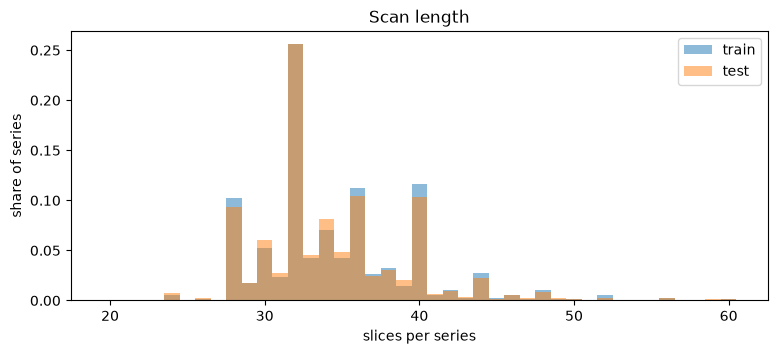

In [24]:
n_slices = meta.groupby(["split", "series"]).size().rename("slices").reset_index()
print(n_slices.groupby("split")["slices"].describe(percentiles=[0.01, 0.5, 0.99]).to_string())

fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.arange(n_slices["slices"].min(), n_slices["slices"].max() + 2) - 0.5
for s in SPLITS:
    ax.hist(n_slices.loc[n_slices["split"] == s, "slices"], bins=bins, density=True, alpha=0.5, label=s)
ax.set(xlabel="slices per series", ylabel="share of series", title="Scan length")
ax.legend()
plt.show()

### 4.3 Slice order and tilt

**Question:** Two keys can order the slices of a series: z, the height of the first pixel (`ImagePositionPatient[2]`), and the position along the slice normal (the direction perpendicular to the slice, from `ImageOrientationPatient`). In a tilted scan, z grows a little faster than the distance between slices, but the order is the same. Do the two keys agree in every series? How many scans are tilted (gantry tilt), and does the tilt change inside a series?

In [25]:
meta = meta.sort_values(["series", "pos"]).reset_index(drop=True)
meta["start"] = meta["x0"].round(1).astype(str) + "," + meta["y0"].round(1).astype(str)
by_series = meta.groupby("series")
order = pd.DataFrame({
    "split": by_series["split"].first(),
    "same_order": by_series["z"].apply(lambda z: z.is_monotonic_increasing),
    "tilt_angles": by_series["tilt_deg"].apply(lambda t: t.round(1).nunique()),
    "start_positions": by_series["start"].nunique(),
    "tilt_deg": by_series["tilt_deg"].max(),
})
print("series where the two keys give different orders:", (~order["same_order"]).groupby(order["split"]).sum().to_dict())
print("tilted series (> 1 degree) %:", (order.groupby("split")["tilt_deg"].apply(lambda t: (t > 1).mean()) * 100).round(1).to_dict())
print(order.groupby("split")["tilt_deg"].describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_string())

series where the two keys give different orders: {'test': 1, 'train': 11}
tilted series (> 1 degree) %: {'test': 51.8, 'train': 57.0}
         count  mean  std  min   50%   90%   99%   max
split                                                 
test    3518.0   8.7  9.5  0.0   5.0  22.0  27.4  30.0
train  21744.0  10.0  9.7  0.0  10.0  22.0  28.0  30.0


The series where the keys disagree. For each of them, `start_positions` and `tilt_angles` count the different (x, y) positions of the first pixel and the different tilt angles among its slices. A regular series has one of each.

In [26]:
mixed = order[~order["same_order"]]
print(f"{len(mixed)} series:", mixed["split"].value_counts().to_dict())
print("start positions per series:", mixed["start_positions"].value_counts().to_dict())
print("tilt angles per series:", mixed["tilt_angles"].value_counts().to_dict())

12 series: {'train': 11, 'test': 1}
start positions per series: {2: 12}
tilt angles per series: {2: 8, 1: 4}


One of them, ordered by z: the slices alternate between two y positions, 20.7 mm apart. Each group is a regular stack 5 mm apart along the normal; together they are two stacks interleaved.

In [27]:
example = meta[meta["series"] == "ID_de9f2b011c"].sort_values("z")
example[["image", "y0", "z", "pos", "tilt_deg"]].head(10).round(2)

,image,y0,z,pos,tilt_deg
758675,ID_7f7280b08,-125.2,23.23,-25.36,22.0
758676,ID_9575a1516,-125.2,28.63,-20.36,22.0
758678,ID_b14c7df96,-104.5,29.41,-11.88,22.0
758677,ID_f3259f90f,-125.2,34.02,-15.35,22.0
758680,ID_ff10193c2,-104.5,34.80,-6.88,22.0
758679,ID_a0fe2d233,-125.2,39.42,-10.35,22.0
758682,ID_d2c796f80,-104.5,40.20,-1.88,22.0
758681,ID_539602a92,-125.2,44.81,-5.35,22.0
758684,ID_012d340eb,-104.5,45.59,3.12,22.0
758683,ID_0eb77e685,-125.2,50.21,-0.35,22.0


In [28]:
several = order[(order["tilt_angles"] > 1) | (order["start_positions"] > 1)]
print("series with more than one tilt angle or start position:", several.groupby("split").size().to_dict())
spread = meta[meta["series"].isin(several.index)].groupby("series").agg(
    x=("x0", lambda v: v.max() - v.min()), y=("y0", lambda v: v.max() - v.min()), tilt=("tilt_deg", lambda v: v.max() - v.min()))
start_spread = np.hypot(spread["x"], spread["y"])
print(f"how far apart the start positions are: {start_spread.min():.1f} to {start_spread.max():.1f} mm (median {start_spread.median():.1f})"
      f" | tilt difference: up to {spread['tilt'].max():.1f} degrees")
print("series where the start position differs by 5 mm or more, or the tilt by 1 degree or more:", ((start_spread >= 5) | (spread["tilt"] >= 1)).sum())

series with more than one tilt angle or start position: {'test': 4, 'train': 41}
how far apart the start positions are: 0.1 to 61.2 mm (median 12.7) | tilt difference: up to 22.0 degrees
series where the start position differs by 5 mm or more, or the tilt by 1 degree or more: 31


### 4.4 Duplicate positions

**Question:** Are there slices at the same position as their neighbour? If so, what are they: copies of the same image, a second reconstruction of the same scan (same anatomy, another sharpness), or a second scan of the same region (same sharpness, but the head may have moved in between)? And do they have the same labels?

In [29]:
meta["gap"] = by_series["pos"].diff()
meta["prev_image"] = by_series["image"].shift()
duplicate = meta["gap"] < 0.01
dup_series = meta.loc[duplicate, "series"].unique()
print(f"slices at the position of the previous slice: {duplicate.sum():,} in {len(dup_series)} series")
print("series with duplicate positions:", meta[meta["series"].isin(dup_series)].groupby("split")["series"].nunique().to_dict())
print(f"distance between the two slices of a pair: at most {meta.loc[duplicate, 'gap'].max():.3f} mm")
print("share of duplicate slices in those series (median): "
      f"{(duplicate.groupby(meta['series']).mean()[dup_series]).median() * 100:.0f}%")
print("of them also with several start positions or tilt angles (4.3):", len(set(dup_series) & set(several.index)))

# A A B B C C: in a series where one stretch was scanned twice, the flagged slices are every other one in a single block
pattern = []
for s, flags in duplicate.groupby(meta["series"]):
    idx = np.flatnonzero(flags.to_numpy())
    if len(idx):
        pattern.append({"pairs": len(idx), "one block": bool(np.all(np.diff(idx) == 2)),
                        "block start": idx.min() / len(flags), "block end": idx.max() / len(flags)})
pattern = pd.DataFrame(pattern)
several_pairs = pattern["pairs"] > 1
print(f"pairs per series: median {pattern['pairs'].median():.0f}, {(~several_pairs).sum()} series with a single pair")
print(f"series with several pairs where the duplicates form one block (A A B B C C ...): {pattern.loc[several_pairs, 'one block'].mean() * 100:.0f}%")
print(f"relative position of the block in the scan (median): {pattern['block start'].median():.2f} to {pattern['block end'].median():.2f}")

slices at the position of the previous slice: 2,333 in 277 series
series with duplicate positions: {'test': 34, 'train': 243}
distance between the two slices of a pair: at most 0.009 mm


share of duplicate slices in those series (median): 18%
of them also with several start positions or tilt angles (4.3): 1


pairs per series: median 8, 19 series with a single pair
series with several pairs where the duplicates form one block (A A B B C C ...): 72%
relative position of the block in the scan (median): 0.20 to 0.57


Do the two slices of a pair differ in any other header field? All fields are compared except the IDs of the file, the position itself and the file size. `FileMetaInformationGroupLength` is left out too: it is the length of the file meta block, which changes with the length of the IDs. Only the fields that differ in at least one pair are listed.

In [30]:
skip = {"file", "split", "image", "read_error", "file_size", "SOPInstanceUID", "MediaStorageSOPInstanceUID",
        "ImagePositionPatient", "FileMetaInformationGroupLength"}
pair_fields = headers.set_index("image")[[c for c in headers.columns if c not in skip]].fillna("")
first, second = pair_fields.loc[meta.loc[duplicate, "prev_image"]].to_numpy(), pair_fields.loc[meta.loc[duplicate, "image"]].to_numpy()
differs = pd.Series((first != second).mean(axis=0) * 100, index=pair_fields.columns)
print(f"fields compared: {len(pair_fields.columns)}")
differs[differs > 0].round(2).rename("pairs with a different value %")

fields compared: 24


ImageOrientationPatient    0.04
WindowCenter               0.09
WindowWidth                1.76
Name: pairs with a different value %, dtype: float64

Forty random pairs, pixel by pixel. The sharpness of a slice is measured as the spread of its fine detail (the image minus a blurred copy) inside the head; a different reconstruction kernel would change it. The shift is the translation that best aligns the two slices (phase correlation).

In [31]:
def slice_hu(split, image):
    ds = pydicom.dcmread(DATA_DIR / f"stage_2_{split}" / f"{image}.dcm")
    return ds.pixel_array.astype(np.float32) * float(ds.RescaleSlope) + float(ds.RescaleIntercept)


def detail(x, mask):
    return np.std((x - cv2.GaussianBlur(x, (0, 0), 2))[mask])


rows = []
for _, r in meta[duplicate].sample(40, random_state=0).iterrows():
    a, b = slice_hu(r["split"], r["image"]), slice_hu(r["split"], r["prev_image"])
    head = (a > -500) & (b > -500)
    (dx, dy), _ = cv2.phaseCorrelate(windowed(a, 40, 400), windowed(b, 40, 400))
    rows.append({
        "series": r["series"], "image": r["image"], "prev_image": r["prev_image"], "split": r["split"],
        "identical": bool((a == b).all()),
        "correlation (brain window)": np.corrcoef(windowed(a, 40, 80).ravel(), windowed(b, 40, 80).ravel())[0, 1],
        "sharpness ratio": max(detail(a, head), detail(b, head)) / min(detail(a, head), detail(b, head)),
        "shift (pixels)": np.hypot(dx, dy),
    })
pairs = pd.DataFrame(rows)
print("identical pairs:", pairs["identical"].sum(), "of", len(pairs))
pairs.drop(columns=["series", "image", "prev_image", "split", "identical"]).describe().loc[["min", "25%", "50%", "75%", "max"]].round(2)

identical pairs: 0 of 40


,correlation (brain window),sharpness ratio,shift (pixels)
min,0.35,1.00,0.18
25%,0.74,1.02,0.52
50%,0.86,1.06,1.01
75%,0.92,1.14,2.82
max,0.99,1.33,41.38


Forty pairs can miss rare copies. The file meta block allows a check of all files: `MediaStorageSOPInstanceUID` (3.2) has 752,800 distinct values for 752,803 train files. Which files share one, and are they the same image?

In [32]:
shared_uid = headers[headers["MediaStorageSOPInstanceUID"].duplicated(keep=False)]
copies = []
for uid, g in shared_uid.groupby("MediaStorageSOPInstanceUID"):
    (a, b), split = g["image"], g["split"].iloc[0]
    pa, pb = (pydicom.dcmread(DATA_DIR / f"stage_2_{split}" / f"{i}.dcm").pixel_array for i in (a, b))
    copies.append({
        "image": a, "other image": b, "split": split, "series": meta.loc[meta["image"] == a, "series"].iloc[0],
        "identical pixels": pa.shape == pb.shape and bool((pa == pb).all()),
        "same labels": bool((labels.reindex([a]).to_numpy() == labels.reindex([b]).to_numpy()).all()),
        "duplicate position": bool(duplicate[meta["image"].isin([a, b])].any()),
    })
pd.DataFrame(copies)

,image,other image,split,series,identical pixels,same labels,duplicate position
0,ID_64f29421d,ID_d47a98002,train,ID_cda7093406,True,True,True
1,ID_de627d90f,ID_eaf3799bc,train,ID_c4cc1ca589,True,True,True
2,ID_8c2286202,ID_ecb2508cb,train,ID_24188141a0,True,True,True


Two pairs: one with a small shift and one with a large shift. Left and middle: the two slices; right: their difference.

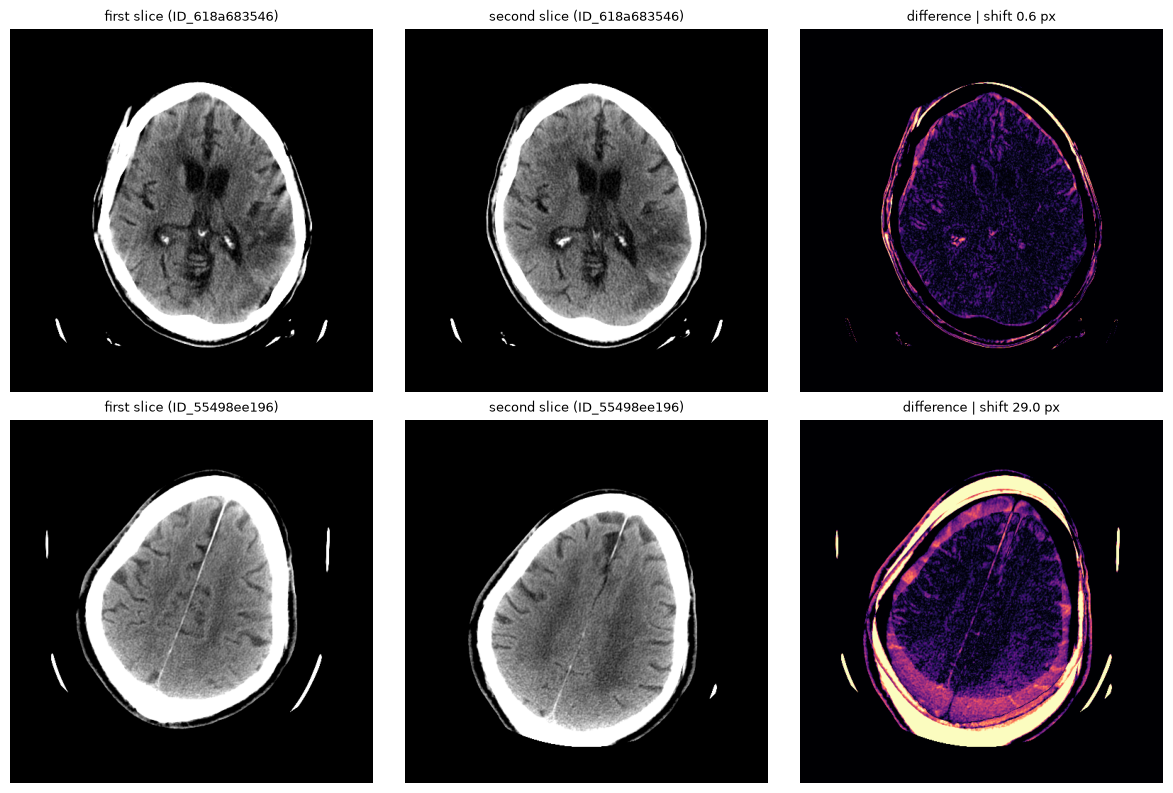

In [33]:
shown = pairs.sort_values("shift (pixels)").iloc[[len(pairs) // 4, -3]]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for row_axes, (_, p) in zip(axes, shown.iterrows()):
    a, b = slice_hu(p["split"], p["image"]), slice_hu(p["split"], p["prev_image"])
    for ax, img, title in [(row_axes[0], b, "first"), (row_axes[1], a, "second")]:
        ax.imshow(windowed(img, 40, 80), cmap="gray")
        ax.set_title(f"{title} slice ({p['series']})", fontsize=9)
    row_axes[2].imshow(np.abs(windowed(a, 40, 80) - windowed(b, 40, 80)), cmap="magma")
    row_axes[2].set_title(f"difference | shift {p['shift (pixels)']:.1f} px", fontsize=9)
    for ax in row_axes:
        ax.axis("off")
plt.tight_layout()
plt.show()

Do the two slices of a pair have the same labels? The duplicate blocks sit in the middle of the scan, where labels change most, so the pairs are also compared with regular neighbours in the same setting: series with a bleed, 0.2–0.6 of the scan height.

In [34]:
prev_labels = by_series[LABELS].shift()
labelled = meta["any"].notna() & prev_labels["any"].notna()
disagree = meta[LABELS].ne(prev_labels)
rel = by_series.cumcount() / (by_series["image"].transform("size") - 1)
bleeding_middle = (by_series["any"].transform("max") == 1) & rel.between(0.2, 0.6)
pd.DataFrame({
    "duplicate pairs": disagree[labelled & duplicate].mean() * 100,
    "regular neighbours": disagree[labelled & ~duplicate].mean() * 100,
    "duplicate pairs, bleed series, middle": disagree[labelled & duplicate & bleeding_middle].mean() * 100,
    "regular neighbours, bleed series, middle": disagree[labelled & ~duplicate & bleeding_middle].mean() * 100,
}).round(1).rename_axis("different label %")

,duplicate pairs,regular neighbours,"duplicate pairs, bleed series, middle","regular neighbours, bleed series, middle"
different label %,,,,
epidural,0.6,0.1,2.2,0.4
intraparenchymal,5.4,1.8,15.9,7.0
intraventricular,5.0,1.3,16.5,5.6
subarachnoid,2.1,1.6,6.9,4.9
subdural,4.0,1.3,10.6,4.1
any,11.9,3.3,36.3,10.4


### 4.5 Slice spacing and missing slices

**Question:** How far apart are the slices (duplicates left out)? Does the spacing change inside a scan, and are there gaps that suggest missing slices?

In [35]:
regular = meta[meta["gap"] >= 0.01].copy()
series_gaps = regular.groupby("series").agg(split=("split", "first"), writer=("writer", "first"), median_gap=("gap", "median"))
spacing_share = pd.crosstab(series_gaps["median_gap"].round(1).rename("median slice spacing (mm)"), series_gaps["split"], normalize="columns") * 100
print("median slice spacing per series, share of series %:")
print(spacing_share.sort_values("train", ascending=False).head(5).round(1).to_string())

median slice spacing per series, share of series %:
split                      test  train
median slice spacing (mm)             
5.0                        94.1   93.5
2.5                         2.1    2.9
6.0                         1.1    1.1
3.8                         0.6    0.5
5.6                         0.2    0.2


The median of a series hides changes along the scan. The **local spacing** of a gap is the median of the five gaps around it. A series whose local spacing goes from one value to another changes its spacing along the scan; a gap much wider than its local spacing suggests a missing slice.

In [36]:
regular["local"] = regular.groupby("series")["gap"].transform(lambda g: g.rolling(5, center=True, min_periods=1).median())
local = regular.groupby("series")["local"]
series_gaps["thin"], series_gaps["thick"] = local.min(), local.max()
series_gaps["spacing change"] = series_gaps["thick"] / series_gaps["thin"] >= 1.5
changes = series_gaps[series_gaps["spacing change"]]
print("series whose spacing changes by 1.5x or more:", changes.groupby("split").size().to_dict(),
      f"({series_gaps['spacing change'].mean() * 100:.1f}% of all series)")
print(f"thinner at the bottom of the scan: {(local.first() < local.last())[changes.index].mean() * 100:.0f}%")
print("thin part (mm, series):", changes["thin"].round(1).value_counts().head(3).to_dict(),
      "| thick part:", changes["thick"].round(1).value_counts().head(3).to_dict())
print("share of each writer's series %:", (series_gaps.groupby("writer")["spacing change"].mean() * 100).round(1).to_dict())
close = regular[regular["gap"] < 1]
print(f"gaps of 0.01-1 mm: {len(close):,} in {close['series'].nunique()} series, "
      f"{close['series'].drop_duplicates().isin(changes.index).mean() * 100:.0f}% of them in a series that changes spacing")

regular["ratio"] = regular["gap"] / regular["local"]
wide = regular[regular["ratio"] > 1.5]
print("\nseries with a gap > 1.5x the local spacing:", wide.groupby("split")["series"].nunique().to_dict())
print("such gaps per series:", wide.groupby("series").size().value_counts().sort_index().to_dict())
print("gap / local spacing:", pd.cut(wide["ratio"], [1.5, 2.5, 3.5, np.inf], labels=["~2", "~3", "more"]).value_counts().sort_index().to_dict())

series whose spacing changes by 1.5x or more: {'test': 502, 'train': 4011} (17.9% of all series)
thinner at the bottom of the scan: 96%
thin part (mm, series): {2.5: 4020, 0.1: 47, 0.2: 43} | thick part: {5.0: 4505, 4.6: 3, 9.9: 1}
share of each writer's series %: {'RSNA Challenge 2019': 0.0, 'dcm4che-1.4.35': 46.7, 'dcm4che-1.4.38': 1.8}
gaps of 0.01-1 mm: 4,719 in 984 series, 97% of them in a series that changes spacing

series with a gap > 1.5x the local spacing: {'test': 22, 'train': 191}
such gaps per series: {1: 147, 2: 35, 3: 5, 4: 8, 5: 8, 6: 3, 7: 2, 8: 2, 9: 2, 12: 1}
gap / local spacing: {'~2': 293, '~3': 29, 'more': 60}


### 4.6 Key findings

- **One series per study** in both splits: 21,744 train scans and 3,518 test scans. Every test patient has one study and none appears in train; train patients have up to 15 studies (2.4). **Folds must be grouped by patient.**
- **Scans have 20–60 slices** in train and test alike (median 33, mean 34.6). A context model needs room for 60 slices, with padding and a mask for shorter scans.
- **57% of train scans and 52% of test scans are tilted** by more than 1°, up to 30°.
- **Sorting by z and sorting along the slice normal give the same order in all but 12 series.**
  - These 12 series hold two stacks of slices: in all of them the first pixel sits at two different (x, y) positions, and in 8 the tilt angle also changes.
  - The slices of the two stacks alternate along the scan (example `ID_de9f2b011c`), so no single order gives one clean volume.
  - The coordinates themselves are consistent. The series simply contains two acquisitions.
  - 45 series (41 train, 4 test) have more than one start position or tilt angle; only these 12 change order. Their start positions differ by 0.1–61 mm (median 13). In 31 of them the start position differs by 5 mm or more, or the tilt by 1° or more.
- **277 series (243 train, 34 test, about 1%) contain slices at the same position as their neighbour:** 2,333 slices at most 0.009 mm apart, a median of 18% of their series. One of these series also has two stacks (above).
  - A series has 8 pairs on median; 19 series have a single pair. In 72% of the series with several pairs, the duplicates form one block (A A B B C C …), on median from 0.20 to 0.57 of the scan height.
  - Of the other 24 header fields, the two slices of a pair differ only in the window values (under 2% of pairs) and the orientation (0.04%).
  - **Three pairs are exact copies:** the same file under two image IDs (same `MediaStorageSOPInstanceUID`, identical pixels, same labels), one pair in each of three series.
  - **The other pairs are not copies.** None of 40 random pairs is identical.
  - **They are not two reconstructions of one scan either.** Their sharpness is nearly the same (ratio median 1.06, at most 1.33), while another reconstruction kernel would change it.
  - **The head has moved between the two:** the shift is 1.0 pixel on median and up to 41, and the brain-window correlation is 0.35–0.99.
  - **So a stretch of the head was most likely scanned twice at the same table positions, and the patient moved in between.** The position in the header is the table position, so it is right for both slices. Whether the scanner or the data curation put both scans into one series cannot be told from the data.
  - **The two slices of a pair disagree on `any` in 11.9% of pairs**, against 3.3% for regular neighbours. The duplicates sit where labels change most, so the fair comparison is within bleed series in the middle of the scan: 36.3% against 10.4%. The second scan of a stretch gets a different label far more often than a neighbour 5 mm away.
  - The sequence model needs a rule for these series and for the 12 above: keep both slices in a fixed order, split the series into two stacks, or keep one. This is decided in 02 and 05.
- **The median slice spacing is 5 mm in 94% of the series**, 2.5 mm in 3%, and 6 mm, 3.75 mm or others in the rest.
- **In 18% of the series the spacing changes along the scan** (4,011 train, 502 test).
  - In 96% of them the bottom part is the thinner one, and in 89% it is 2.5 mm below and 5 mm above. This matches a common head CT protocol with thinner slices through the skull base.
  - Almost all of them come from the 1.4.35 writer: 47% of its series change spacing, against 1.8% of the 1.4.38 series and none of the "RSNA Challenge 2019" ones.
  - Where the thin and the thick part meet, the gap is often irregular: 984 series have a gap of 0.01–1 mm, 97% of them in a series that changes spacing.
  - So a neighbour can be 2.5 or 5 mm away within one scan, and up to 6 mm across scans. This supports a z-distance input (used by the 1st place).
- **213 series (191 train, 22 test) have gaps wider than 1.5 × their local spacing**, 147 of them only one. Most of these gaps (293 of 382) are about twice the local spacing: most likely missing slices. The z-distance input covers them too.

## 5. Labels along the scan

**Question:** How do bleeds sit inside a scan? This decides how much a model that sees the neighbouring slices can gain.

### 5.1 Scan-level prevalence

The number of positive slices per positive series (the share of series with each label is in 2.4).

In [37]:
train = meta[meta["split"] == "train"].copy()
train["slice"] = train.groupby("series").cumcount()
train["n_slices"] = train.groupby("series")["image"].transform("size")
train["rel_pos"] = train["slice"] / (train["n_slices"] - 1)

series_labels = train.groupby("series")[LABELS].sum()
pd.DataFrame({
    "positive slices per positive series (mean)": series_labels[series_labels > 0].mean().round(1),
    "(median)": series_labels[series_labels > 0].median(),
    "(max)": series_labels.max(),
})

,positive slices per positive series (mean),(median),(max)
epidural,8.9,8.0,25.0
intraparenchymal,6.8,6.0,31.0
intraventricular,7.1,6.0,32.0
subarachnoid,9.1,7.0,40.0
subdural,12.4,12.0,39.0
any,12.2,12.0,40.0


### 5.2 Are positive slices contiguous?

**Question:** Annotators could mark the first and last slice of a bleed and let the tool fill in the slices between. Do positive slices then form one unbroken run along the scan, or several?

In [38]:
new_series = train["series"] != train["series"].shift()
runs = {}
for label in LABELS:
    y = train[label]
    starts = (y == 1) & ((y.shift() != 1) | new_series)
    n_runs = starts.groupby(train["series"]).sum()
    runs[label] = n_runs[n_runs > 0].clip(upper=4).value_counts(normalize=True).sort_index() * 100
runs = pd.DataFrame(runs).T.fillna(0).round(1)
runs.columns = ["1 run", "2 runs", "3 runs", "4+ runs"]
runs

,1 run,2 runs,3 runs,4+ runs
epidural,89.5,9.0,0.8,0.6
intraparenchymal,82.2,14.0,2.4,1.4
intraventricular,79.1,18.3,1.7,0.9
subarachnoid,67.8,22.6,6.6,3.1
subdural,82.6,13.9,2.3,1.3
any,75.8,18.3,4.0,1.9


The simplest break is a single negative slice between two positive ones (+ − +). How often does it occur?

In [39]:
by_train = train.groupby("series")[LABELS]
holes = ((train[LABELS] == 0) & (by_train.shift() == 1) & (by_train.shift(-1) == 1)).sum()
pd.DataFrame({"single negative slice between positives": holes, "per 1,000 positive slices": (holes / train[LABELS].sum() * 1000).round(1)})

,single negative slice between positives,"per 1,000 positive slices"
epidural,27,8.6
intraparenchymal,660,18.3
intraventricular,500,19.1
subarachnoid,873,24.5
subdural,607,12.9
any,1757,16.3


### 5.3 Position in the scan

**Question:** Where in the stack (relative position, 0 = first slice at the bottom, 1 = last at the top) is each subtype found?

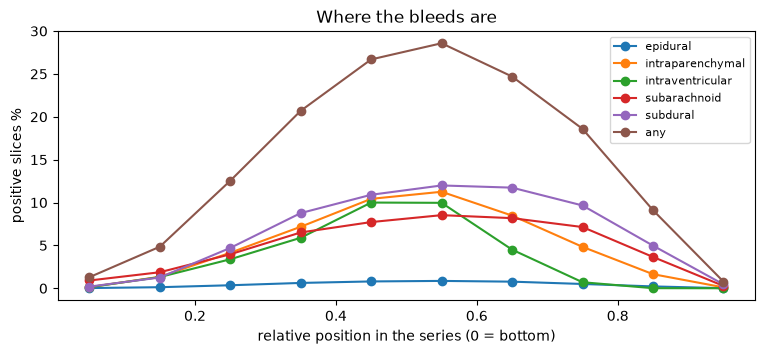

relative position,0.0-0.1,0.1-0.2,0.2-0.3,0.3-0.4,0.4-0.5,0.5-0.6,0.6-0.7,0.7-0.8,0.8-0.9,0.9-1.0
epidural,0.0,0.1,0.4,0.6,0.8,0.9,0.8,0.5,0.2,0.0
intraparenchymal,0.1,1.3,4.1,7.2,10.4,11.3,8.5,4.8,1.6,0.1
intraventricular,0.1,1.3,3.4,5.9,10.0,10.0,4.5,0.7,0.0,0.0
subarachnoid,0.9,1.9,4.0,6.5,7.7,8.5,8.2,7.1,3.7,0.3
subdural,0.2,1.3,4.7,8.8,10.9,12.0,11.7,9.7,5.0,0.5
any,1.3,4.8,12.5,20.7,26.7,28.6,24.7,18.6,9.1,0.8


In [40]:
bins = pd.cut(train["rel_pos"], np.linspace(0, 1, 11), include_lowest=True)
by_position = train.groupby(bins, observed=True)[LABELS].mean() * 100

fig, ax = plt.subplots(figsize=(9, 3.5))
for label in LABELS:
    ax.plot(np.linspace(0.05, 0.95, 10), by_position[label], marker="o", label=label)
ax.set(xlabel="relative position in the series (0 = bottom)", ylabel="positive slices %", title="Where the bleeds are")
ax.legend(fontsize=8)
plt.show()
by_position.set_axis([f"{a:.1f}-{a + 0.1:.1f}" for a in np.linspace(0, 0.9, 10)]).rename_axis("relative position").round(1).T

### 5.4 Agreement with neighbours

**Question:** How often does the next slice have the same label? A first idea of how much information the neighbours carry.

In [41]:
nxt = train.groupby("series")[LABELS].shift(-1)
rows = {}
for label in LABELS:
    valid = nxt[label].notna()
    y, y_next = train.loc[valid, label], nxt.loc[valid, label]
    rows[label] = {
        "same label %": (y == y_next).mean() * 100,
        "next positive | positive %": y_next[y == 1].mean() * 100,
        "next positive | negative %": y_next[y == 0].mean() * 100,
    }
pd.DataFrame(rows).T.round(2)

,same label %,next positive | positive %,next positive | negative %
epidural,99.89,87.19,0.05
intraparenchymal,98.18,81.60,0.96
intraventricular,98.72,82.17,0.66
subarachnoid,98.42,83.63,0.82
subdural,98.69,89.80,0.70
any,96.71,88.78,1.91


### 5.5 Key findings

- **A positive scan has 12 positive slices on average** (median 12, up to 40). Subdural bleeds are the longest (12.4 slices) and intraparenchymal the shortest (6.8).
- **Positive slices mostly form one run along the scan, but not always.** For `any`, 76% of positive scans have one run, 18% two and 6% three or more. Subarachnoid is the most broken up (68% one run), epidural the least (90%).
  - The simplest break, one negative slice between two positive ones, occurs 1,757 times for `any` (16 per 1,000 positive slices), most often for subarachnoid (25 per 1,000).
  - Some breaks are real (two separate bleeds). Others are likely gaps left by the single reader of each training exam (data paper).
- **Bleeds sit in the middle of the scan.** At relative position 0.5–0.6, 29% of the slices are positive. The bottom and top tenths are almost always negative (1.3% and 0.8%). Intraventricular blood is the most concentrated in the middle; subdural and subarachnoid blood reach higher.
- **Neighbours carry a lot of information.**
  - After a positive slice, the next one is positive 82–90% of the time, depending on the subtype.
  - After a negative slice, the next one is positive only 0.05–1.9% of the time.
  - This is the signal the context models (05) use, and the reason every top solution had one.

## 6. Images

Reading all ~874K files belongs to the cache step (02). Here pixels are read for a random sample of 300 train and 100 test series, all their slices.

In [42]:
rng = np.random.default_rng(0)
sample_series = np.concatenate([
    rng.choice(meta.loc[meta["split"] == s, "series"].unique(), n, replace=False) for s, n in [("train", 300), ("test", 100)]])
sample = meta[meta["series"].isin(sample_series)].copy()


def path_of(row):
    return DATA_DIR / f"stage_2_{row['split']}" / f"{row['image']}.dcm"


print(f"sample: {len(sample):,} slices in {len(sample_series)} series")
train_all, train_part = meta[meta["split"] == "train"], sample[sample["split"] == "train"]
for name, df in [("train sample", train_part), ("all train", train_all)]:
    print(f"{name:12s} any: {df['any'].mean() * 100:.1f}% of slices, {df.groupby('series')['any'].max().mean() * 100:.1f}% of series")

sample: 13,801 slices in 400 series


train sample any: 16.0% of slices, 44.7% of series
all train    any: 14.3% of slices, 40.8% of series


### 6.1 From stored values to Hounsfield units

**Question:** Stored pixel values become Hounsfield units (HU) through `RescaleSlope` and `RescaleIntercept`: air is about −1000 HU, water 0, brain tissue 20–45, fresh blood about 50–100 and bone from several hundred to above 1000. What goes wrong with the files from 3.3, and what does the fix look like?

For the files of 3.3 the header says the pixels are unsigned (`PixelRepresentation` 0) with an intercept of 0 or 1. The stored values, however, are the HU values modulo 4096: positive HU such as brain are stored as they are, but negative HU such as air have wrapped around to the top of the 12-bit range (−1000 is stored as 3,096). Read with the header's rule, air becomes about +3,000 HU and looks brighter than bone.

The fix (from Jeremy Howard's Kaggle notebook "Cleaning the data for rapid prototyping (fastai)") adds 1000, subtracts 4096 from values of 4096 and above, and uses an intercept of −1000. Stored values from 3,096 up become −1000 to −1 HU; lower values keep their HU. This assumes that no pixel lies below −1000 HU. A plain signed 12-bit reading would draw the line at 2,048 instead, and would turn dense bone above 2,047 HU negative. The check below also counts the pixels where the two readings differ.

In all files the pixels are cast to float before the rescale, because `uint16` plus a negative intercept wraps around in the same way.

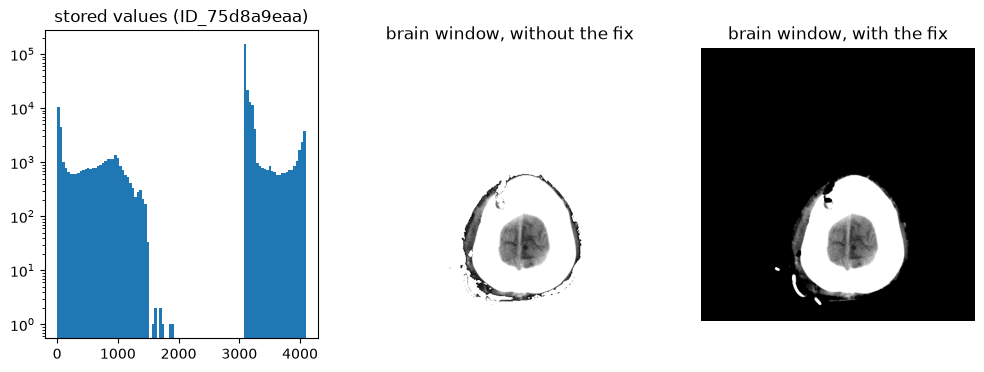

In [43]:
def to_hu(ds, fix=True):
    pixels = ds.pixel_array.astype(np.float32)
    intercept, slope = float(ds.RescaleIntercept), float(ds.RescaleSlope)
    if fix and ds.BitsStored == 12 and ds.PixelRepresentation == 0 and intercept > -100:
        pixels += 1000
        pixels[pixels >= 4096] -= 4096
        intercept = -1000
    return pixels * slope + intercept


bad = suspicious.iloc[len(suspicious) // 2]
ds = pydicom.dcmread(path_of(bad))
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].hist(ds.pixel_array.ravel(), bins=100)
axes[0].set(title=f"stored values ({bad['image']})", yscale="log")
for ax, fix in zip(axes[1:], [False, True]):
    ax.imshow(windowed(to_hu(ds, fix=fix), 40, 80), cmap="gray")
    ax.set(title=f"brain window, {'with' if fix else 'without'} the fix")
    ax.axis("off")
plt.show()

**Question:** Does the fix work on all 123 files, not only on the one shown? A CT slice always has air around the head, so its 5th percentile should be about −1000 HU or lower.

In [44]:
rows, between = [], []
for _, r in suspicious.iterrows():
    ds = pydicom.dcmread(path_of(r))
    before, after = to_hu(ds, fix=False), to_hu(ds)
    tissue = after[(after > -100) & (after < 150)]
    rows.append({
        "stored values >= 3000 %": (ds.pixel_array >= 3000).mean() * 100,
        "5th percentile HU, without the fix": np.percentile(before, 5),
        "5th percentile HU, with the fix": np.percentile(after, 5),
        "soft tissue median HU, with the fix": np.median(tissue) if tissue.size > 1000 else np.nan,
    })
    # stored 2,048-3,095: the fix keeps these positive, a plain signed reading would make them negative.
    # Each such pixel is judged by the median of its unambiguous neighbours (7 x 7 window).
    differ = (ds.pixel_array >= 2048) & (ds.pixel_array < 3096)
    clear = np.where(differ, np.nan, after)
    windows = [clear[max(y - 3, 0):y + 4, max(x - 3, 0):x + 4] for y, x in zip(*np.nonzero(differ))]
    around = np.array([np.nanmedian(w) if np.isfinite(w).any() else np.nan for w in windows])
    between.append({"size": differ.size, "pixels": differ.sum(), "value 3000": (ds.pixel_array[differ] == 3000).sum(),
                    "air": (around < -900).sum(), "soft tissue": ((around >= -900) & (around <= 300)).sum(),
                    "bone": (around > 300).sum()})
display(pd.DataFrame(rows).describe().loc[["count", "min", "50%", "max"]].round(0))

between = pd.DataFrame(between)
n_px, n_differ = between["size"].sum(), between["pixels"].sum()
print(f"pixels where the fix and a plain signed reading differ: {n_differ:,} of {n_px:,} "
      f"({n_differ / n_px * 100:.4f}%) in {(between['pixels'] > 0).sum()} files, {between['value 3000'].sum():,} of them exactly 3000")
print(f"their unambiguous neighbours: bone {between['bone'].sum():,} | soft tissue {between['soft tissue'].sum():,} | "
      f"air {between['air'].sum():,} | none (inside a patch of such values) {n_differ - between[['bone', 'soft tissue', 'air']].sum().sum():,}")

,stored values >= 3000 %,"5th percentile HU, without the fix","5th percentile HU, with the fix","soft tissue median HU, with the fix"
count,123.0,123.0,123.0,121.0
min,62.0,21.0,-1000.0,-61.0
50%,79.0,30.0,-1000.0,28.0
max,100.0,3097.0,-1000.0,41.0


pixels where the fix and a plain signed reading differ: 2,818 of 32,243,712 (0.0087%) in 31 files, 1,900 of them exactly 3000
their unambiguous neighbours: bone 1,974 | soft tissue 366 | air 7 | none (inside a patch of such values) 471


**Question:** Are the other unusual intercepts wrong too (intercept 0 with signed pixels, or −1000)? Without any fix, 30 random files per group: the median of the soft-tissue pixels (−100 to 150 HU) should be brain, about 30 HU, and the 5th percentile should be air or padding (−1000 or lower).

In [45]:
rows = []
for (storage, intercept), g in meta.groupby(["storage", "intercept"]):
    soft, low = [], []
    for _, r in g.sample(min(30, len(g)), random_state=0).iterrows():
        hu = to_hu(pydicom.dcmread(path_of(r)), fix=False)
        tissue = hu[(hu > -100) & (hu < 150)]
        soft.append(np.median(tissue) if tissue.size > 1000 else np.nan)  # near-empty slices have no tissue
        low.append(np.percentile(hu, 5))
    rows.append({"storage": storage, "intercept": intercept, "images": len(g),
                 "soft tissue median HU": np.nanmedian(soft), "5th percentile HU": np.median(low)})
pd.DataFrame(rows).set_index(["storage", "intercept"])

images  soft tissue median HU  5th percentile HU
storage         intercept                                                  
12 bit / repr 0 -1024.0    385432                   28.0            -1005.0
                -1000.0      7789                   30.0            -1000.0
                 0.0           73                   37.0               31.0
                 1.0           50                   31.0               28.0
12 bit / repr 1  0.0         3089                   30.0            -1000.0
16 bit / repr 1 -1024.0    474055                   29.0            -3024.0
                 0.0         3547                   29.0            -3024.0

### 6.2 Windows

**Question:** A window maps a HU range to grey levels. What does one slice look like through the brain (40/80), subdural (80/200) and bone (600/2800) windows?

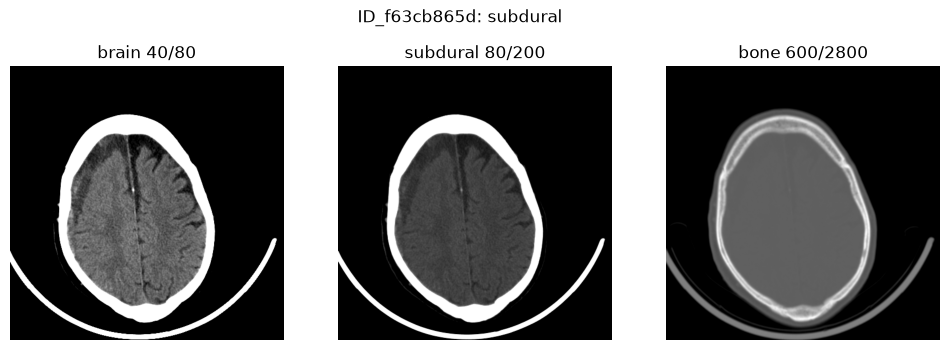

In [46]:
WINDOWS = {"brain 40/80": (40, 80), "subdural 80/200": (80, 200), "bone 600/2800": (600, 2800)}

candidates = train[train["series"].isin(sample_series) & (train["subdural"] == 1) & train["rel_pos"].between(0.6, 0.8)]
example = candidates.iloc[len(candidates) // 2]
hu = to_hu(pydicom.dcmread(path_of(example)))
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, (c, w)) in zip(axes, WINDOWS.items()):
    ax.imshow(windowed(hu, c, w), cmap="gray")
    ax.set(title=name)
    ax.axis("off")
plt.suptitle(f"{example['image']}: subdural")
plt.show()

Each subtype with its neighbours: one slice that has only this subtype (middle), with the slices below and above, in the brain window.

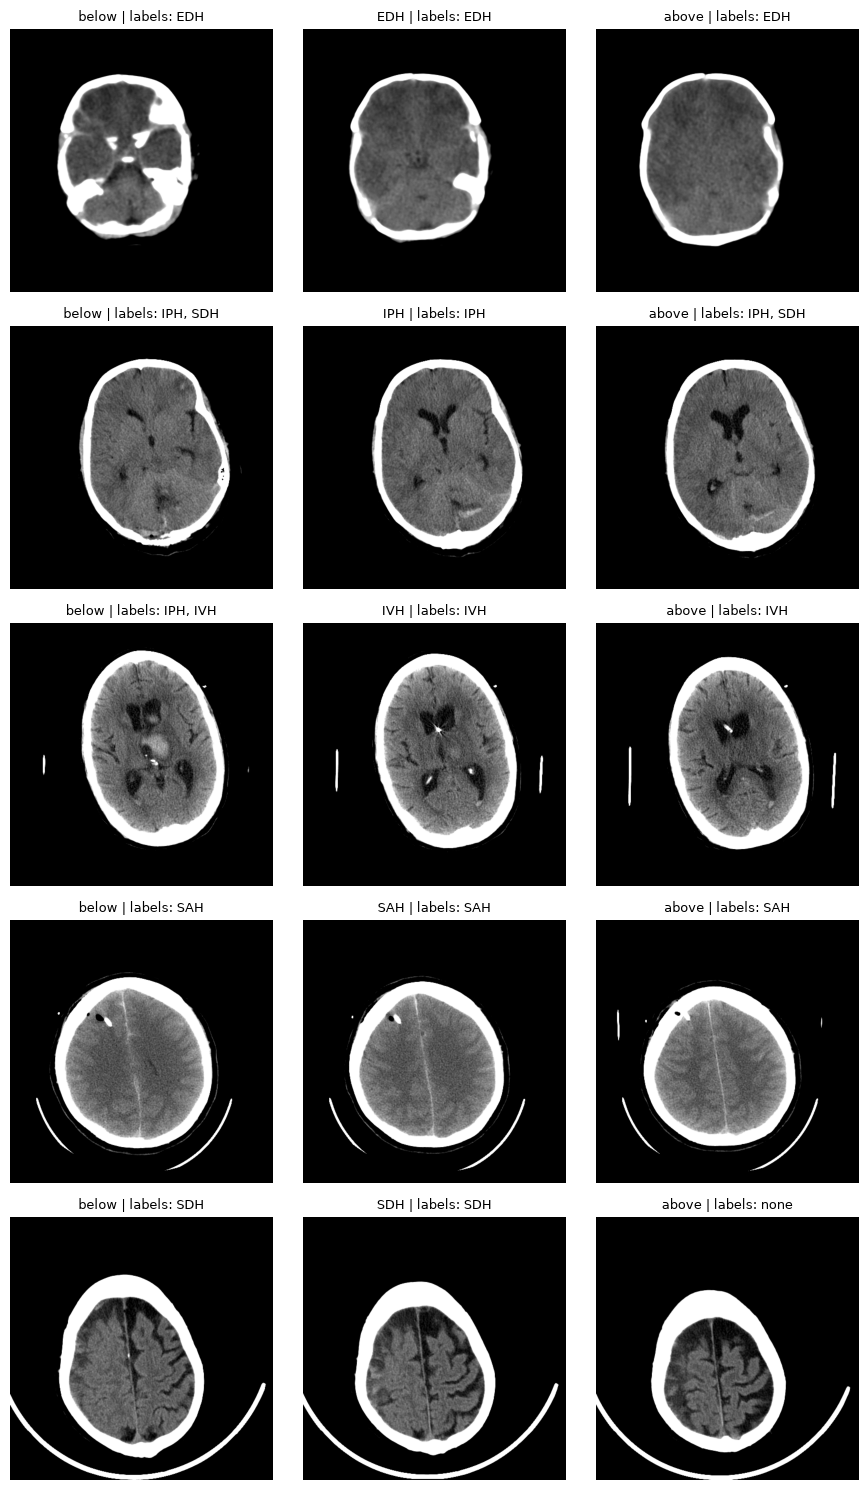

In [47]:
fig, axes = plt.subplots(len(SUBTYPES), 3, figsize=(9, 3 * len(SUBTYPES)))
train_sample = sample[sample["split"] == "train"].reset_index(drop=True)
same_series = train_sample["series"]
inside = (same_series.shift(1) == same_series) & (same_series.shift(-1) == same_series)  # both neighbours exist
for row_axes, subtype in zip(axes, SUBTYPES):
    only = train_sample[inside & (train_sample[subtype] == 1) & (train_sample[SUBTYPES].sum(axis=1) == 1)]
    pool = only if len(only) else train_sample[inside & (train_sample[subtype] == 1)]
    i = pool.index[len(pool) // 2]
    for ax, j in zip(row_axes, [i - 1, i, i + 1]):
        r = train_sample.loc[j]
        ax.imshow(windowed(to_hu(pydicom.dcmread(path_of(r))), 40, 80), cmap="gray")
        tags = [SHORT[s] for s in SUBTYPES if r[s] == 1]
        where = SHORT[subtype] if j == i else ("below" if j < i else "above")
        ax.set_title(f"{where} | labels: {', '.join(tags) or 'none'}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

### 6.3 HU range and extreme values

**Question:** What range do the values cover, and which extremes need clipping (padding outside the scanned circle, values near ±32768)? Per-slice statistics for the sample, after the fix.

In [48]:
def slice_stats(row):
    hu = to_hu(pydicom.dcmread(path_of(row)))
    return {
        "image": row["image"], "min": hu.min(), "p99": np.percentile(hu, 99), "max": hu.max(),
        "brain_window %": ((hu >= 0) & (hu <= 80)).mean() * 100,
        "not_air %": (hu > -500).mean() * 100,
        "bone %": (hu > 300).mean() * 100,
    }


with ThreadPoolExecutor(16) as pool:
    stats = pd.DataFrame(pool.map(slice_stats, [r for _, r in sample.iterrows()]))
sample = sample.merge(stats, on="image")
print("most common minimum values (HU, slices):", sample["min"].value_counts().head(6).to_dict())
sample.groupby("split").agg(**{
    "slices": ("image", "size"),
    "lowest value (HU)": ("min", "min"),
    "highest value (HU)": ("max", "max"),
    "slices with values below -1024 %": ("min", lambda m: (m < -1024).mean() * 100),
    "slices with values above 3071 %": ("max", lambda m: (m > 3071).mean() * 100),
    "99th percentile of a slice, median (HU)": ("p99", "median"),
}).round(1).T

most common minimum values (HU, slices): {-3024.0: 5146, -1024.0: 2843, -2048.0: 1743, -1018.0: 379, -1000.0: 340, -1020.0: 339}


split,test,train
slices,3391.0,10410.000000
lowest value (HU),-3024.0,-32968.000000
highest value (HU),30543.0,31440.000000
slices with values below -1024 %,49.5,50.099998
slices with values above 3071 %,0.7,0.900000
"99th percentile of a slice, median (HU)",1157.0,1160.000000


Does the padding value depend on the site? Share of sampled slices per writer by their minimum value:

In [49]:
padding = sample["min"].map({-3024.0: "-3024", -2048.0: "-2048", -1024.0: "-1024"}).fillna("other").rename("minimum (HU)")
(pd.crosstab(sample["writer"], padding, normalize="index") * 100).round(1)

minimum (HU),-1024,-2048,-3024,other
writer,,,,
RSNA Challenge 2019,20.2,0.0,0.0,79.8
dcm4che-1.4.35,0.0,0.0,100.0,0.0
dcm4che-1.4.38,45.5,41.0,2.3,11.2


### 6.4 Slices with almost no brain

**Question:** How many slices show almost no brain, where in the scan are they, and are any of them positive? "Almost no brain" means few pixels in 0–80 HU, the range of brain tissue and fresh blood; such a slice is not black, it can still show bone, skin or the headrest.

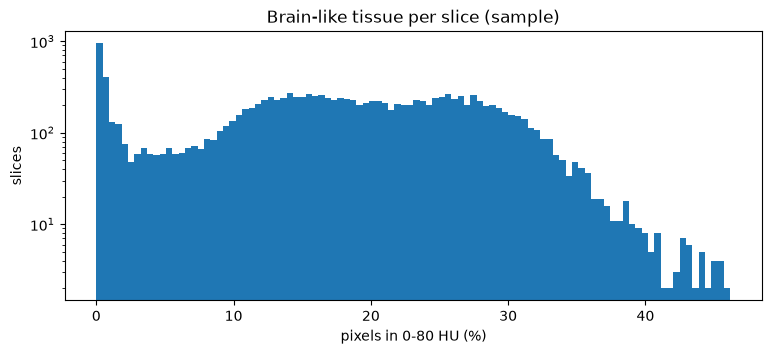

< 1% brain-window pixels: 10.0% of slices | positive (train): 0 of 1051
< 2% brain-window pixels: 11.9% of slices | positive (train): 0 of 1239
< 5% brain-window pixels: 14.7% of slices | positive (train): 19 of 1529


In [50]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(sample["brain_window %"], bins=100)
ax.set(xlabel="pixels in 0-80 HU (%)", ylabel="slices", yscale="log", title="Brain-like tissue per slice (sample)")
plt.show()

for limit in [1, 2, 5]:
    low = sample[sample["brain_window %"] < limit]
    print(f"< {limit}% brain-window pixels: {len(low) / len(sample) * 100:.1f}% of slices | positive (train): {int(low['any'].sum())} of {low['any'].notna().sum()}")

Where are the slices with under 2% brain-window pixels, and what do they show?

in the top half of the scan: 100%
position counted from the top slice: {0: 395, 1: 380, 2: 333, 3: 261, 4: 150, 5: 72, 6: 25, 7: 8, 8: 3, 9: 3, 10: 2, 11: 2, 12: 2, 13: 2, 14: 1, 15: 1, 16: 1}
pixels that are not air (> -500 HU), median: 8.4% | bone (> 300 HU), median: 2.2%
almost only air (< 1% not air): 9%


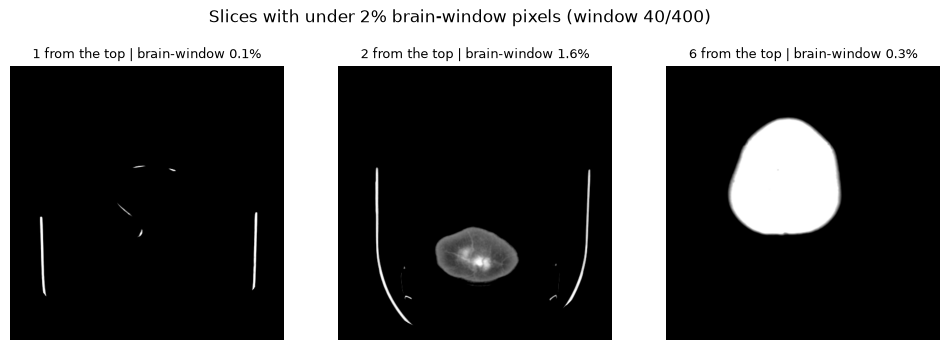

In [51]:
sample["from_top"] = sample.groupby("series").cumcount(ascending=False)  # 0 = last (highest) slice
sample["rel_pos"] = sample.groupby("series").cumcount() / (sample.groupby("series")["image"].transform("size") - 1)
low = sample[sample["brain_window %"] < 2]
print(f"in the top half of the scan: {(low['rel_pos'] >= 0.5).mean() * 100:.0f}%")
print("position counted from the top slice:", low["from_top"].value_counts().sort_index().to_dict())
print(f"pixels that are not air (> -500 HU), median: {low['not_air %'].median():.1f}% | bone (> 300 HU), median: {low['bone %'].median():.1f}%")
print(f"almost only air (< 1% not air): {(low['not_air %'] < 1).mean() * 100:.0f}%")

examples = low.sort_values("not_air %").iloc[[len(low) // 10, len(low) // 2, len(low) * 9 // 10]]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (_, r) in zip(axes, examples.iterrows()):
    ax.imshow(windowed(to_hu(pydicom.dcmread(path_of(r))), 40, 400), cmap="gray")
    ax.set_title(f"{int(r['from_top'])} from the top | brain-window {r['brain_window %']:.1f}%", fontsize=9)
    ax.axis("off")
plt.suptitle("Slices with under 2% brain-window pixels (window 40/400)")
plt.show()

The series reported in the [forum](https://www.kaggle.com/competitions/rsna-intracranial-hemorrhage-detection/discussion/116271) as a chest CT (`ID_04e8aba14f`): first, middle and last slice.

slices: 48 | split: train | positive slices: 0


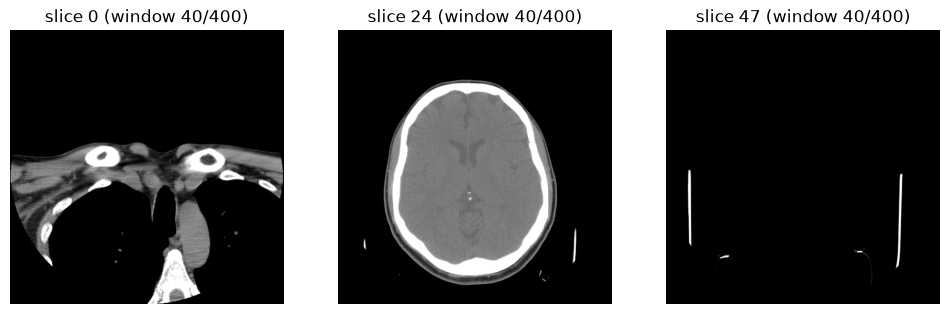

In [52]:
chest = meta[(meta["series"] == "ID_04e8aba14f") | (meta["study"] == "ID_04e8aba14f")]
print(f"slices: {len(chest)} | split: {', '.join(chest['split'].unique())} | positive slices: {int(chest['any'].sum())}")
if len(chest):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, k in zip(axes, [0, len(chest) // 2, len(chest) - 1]):
        ax.imshow(windowed(to_hu(pydicom.dcmread(path_of(chest.iloc[k]))), 40, 400), cmap="gray")
        ax.set(title=f"slice {k} (window 40/400)")
        ax.axis("off")
    plt.show()

### 6.5 Key findings

- **The fix works on all 123 files.**
  - In these files 62–100% of the stored values are 3,000 or more: air that has wrapped around.
  - Without the fix their 5th percentile is +21 to +3,097 HU, so there is no air at all, and the background comes out bright.
  - With the fix the 5th percentile is −1000 HU in every file, and soft tissue sits at a median of 28 HU.
  - The fix and a plain signed 12-bit reading differ only on stored values of 2,048–3,095: 2,818 pixels (0.009%) in 31 files, 1,900 of them exactly 3,000. Their unambiguous neighbours are bone (1,974) or soft tissue (366), almost never air (7). So they are dense bone, which the fix reads correctly; a plain signed reading would make them −2,048 to −1,001 HU.
- **The other unusual intercepts are correct**, judged on 30 random files per storage group and intercept. Signed files with intercept 0, and files with −1000, already give brain at 28–30 HU and air or padding at the bottom of the range. Only the 0/1 intercepts of the 12 bit unsigned group give a 5th percentile near +30 HU (no air), and these are the 123 files.
- **The three fixed windows** show the contrast inside the brain (40/80), blood next to the skull (80/200) and the skull itself (600/2800).
- **Values range far beyond the windows.**
  - Outside the scanned circle there is padding at −3,024, −2,048 or −1,024 HU. −3,024 is the most common minimum, found on 37% of sampled slices; half of the slices have values below −1,024 HU.
  - At the top end, extremes reach +31,440 HU, but only about 1% of slices have values above 3,071 HU, and the 99th percentile of a slice is about 1,160 HU on median. The lowest value is −32,968 HU.
  - Clipping to [−1024, 3071] removes the extremes and sets all padding to −1,024. The widest window we use ends at 2,000 HU, so the clip changes nothing visible.
- **The padding value gives the site away.** All sampled slices of the 1.4.35 writer have −3,024 as their minimum; the 1.4.38 writer mostly has −1,024 or −2,048, and the "RSNA Challenge 2019" writer other values (80%) or −1,024.
  - So a model can tell the sites apart from the pixels, and the sites differ in bleed rate (6–35%): a possible shortcut.
  - Clipping to −1,024 removes this clue, but not necessarily other traits of a site.
- **11.9% of the sampled slices show almost no brain**: under 2% of their pixels are in 0–80 HU. None of the 1,239 train slices among them is positive. With a 5% limit the share is 14.7%, with 19 positives.
  - **They are the top of the scan.** All of them are in the top half, and 99% are among the 8 highest slices.
  - They cut through the top of the skull (median 2.2% bone pixels) or lie above the head (9% are almost only air, with the headrest).
  - The bottom slices are not among them, because they still show brainstem and cerebellum.
  - They are near-certain, not certain, negatives: on the stage-1 training data, Jeremy Howard's cleaning notebook counts 61 positives among 70,673 slices under a 2% limit. The 4th and 10th places gave them a fixed low prediction. The exact count over all slices comes from the cache pass in 02.
- **The "chest CT" series is a long scan from the shoulders to above the head.** It contains a normal brain in the middle and has no positive labels. It can stay.

## 7. Is the test set like the train set?

**Question:** If the test scans came from a different population, validation scores on train would be misleading. Compare storage groups, image size, pixel spacing, slices per series and tilt (labels of the test set are not public).

In [53]:
series_meta = meta.groupby("series").agg(
    split=("split", "first"), storage=("storage", "first"), writer=("writer", "first"),
    slices=("image", "size"), spacing=("spacing", "median"), tilt=("tilt_deg", "max"), size512=("rows", lambda r: (r == 512).all()))
series_meta["slice spacing"] = series_gaps["median_gap"]
series_meta["spacing change"] = series_gaps["spacing change"]
series_meta["duplicates"] = series_meta.index.isin(dup_series)
compare = pd.concat([
    series_meta.groupby("split")["storage"].value_counts(normalize=True).unstack().mul(100).add_prefix("% series: "),
    series_meta.groupby("split")["writer"].value_counts(normalize=True).unstack().mul(100).add_prefix("% series: "),
    series_meta.groupby("split").agg(**{
        "median slices": ("slices", "median"), "max slices": ("slices", "max"),
        "median pixel spacing (mm)": ("spacing", "median"), "% tilted": ("tilt", lambda t: (t > 1).mean() * 100),
        "% slice spacing 5 mm": ("slice spacing", lambda g: (g.round(1) == 5).mean() * 100),
        "% slice spacing < 4 mm": ("slice spacing", lambda g: (g < 4).mean() * 100),
        "% spacing changes along the scan": ("spacing change", lambda c: c.mean() * 100),
        "% with duplicate positions": ("duplicates", lambda d: d.mean() * 100),
        "% not 512": ("size512", lambda s: (~s).mean() * 100)}),
], axis=1)
compare.T.round(2)

split,test,train
% series: 12 bit / repr 0,49.86,44.99
% series: 12 bit / repr 1,0.74,0.36
% series: 16 bit / repr 1,49.40,54.65
% series: RSNA Challenge 2019,36.33,33.09
% series: dcm4che-1.4.35,29.22,38.40
% series: dcm4che-1.4.38,34.45,28.50
median slices,33.00,33.00
max slices,60.00,60.00
median pixel spacing (mm),0.49,0.49
% tilted,51.76,56.97


The test labels are not public, but the data paper gives the share of bleeding slices in the test set: 13.1%. What would it be if each site kept its train bleed rate in the test set?

In [54]:
site_rate = meta[meta["split"] == "train"].groupby("writer")["any"].mean()
test_mix = meta.loc[meta["split"] == "test", "writer"].value_counts(normalize=True)
display(pd.DataFrame({"any % (train)": site_rate * 100, "share of test images %": test_mix * 100}).round(1))
print(f"expected share of bleeding test slices: {(site_rate * test_mix).sum() * 100:.1f}% | data paper: 13.1%")

,any % (train),share of test images %
writer,,
RSNA Challenge 2019,6.0,37.0
dcm4che-1.4.35,7.6,30.2
dcm4che-1.4.38,34.5,32.8


expected share of bleeding test slices: 15.9% | data paper: 13.1%


### 7.1 Key findings

- **The test set looks like the train set:**
  - same scan length (median 33, maximum 60 slices);
  - same pixel spacing (0.49 mm) and median slice spacing (94% at 5 mm);
  - about 1% of series with duplicate positions in both;
  - all test images 512 × 512.
- **The site mix differs.** The 1.4.38 writer is the site with 34.5% bleeding slices in train. It makes up 34% of test series but 28.5% of train series, while 1.4.35 drops from 38% to 29%.
  - The test set also has fewer tilted scans (52% vs 57%).
  - It has fewer scans that change spacing (14% vs 18%), which fits the smaller share of 1.4.35, the site with the thin bottom slices.
- **Yet the test set has fewer bleeds overall** (13.1% of slices vs 14.3%). The test labels are not in the download; the 13.1% comes from Table 2 of the [data paper](https://doi.org/10.1148/ryai.2020190211).
  - If each site kept its train bleed rate, the test mix of sites would give 15.9% bleeding slices, not 13.1%.
  - So, if the writer marks the site, the share of bleeds within at least one site must be lower in test than in train. This matches the paper, which says the test set was balanced across sites. A per-site calibration shift is possible, which matters for 06.

## Summary

- **The data:** 874,035 CT slices (459 GB).
  - Train: 752,803 slices from 21,744 scans of 18,938 patients.
  - Test: 121,232 slices from 3,518 scans, one scan per patient, no patient shared with train.
  - Files and label tables match one to one. One train file (`ID_6431af929`) is corrupt, four images have duplicated label rows, and three images are stored twice under two IDs.
- **The labels:**
  - A bleed is on 14.3% of the slices, but in 41% of the scans and 40% of the patients.
  - Subdural is the most common subtype per slice and epidural the rarest (310 patients).
  - 30% of bleeding slices have more than one subtype, and `any` is always the maximum of the five.
- **The sites:** the files come from three different writers, most likely the three sites. Their bleed rates differ widely (6.0%, 7.6% and 34.5% of slices), and the test set has a different mix of them. In the pixel sample, the padding value alone tells the sites apart.
- **The scans:**
  - One series per study, with 20–60 slices, mostly 5 mm apart (2.5–6 mm). 57% of the scans are tilted.
  - In 18% of the scans, almost all from one site, the bottom of the head is cut at 2.5 mm and the rest at 5 mm.
  - About 1.3% of the series (321) are not one regular stack:
    - 277 contain a stretch of the head scanned twice;
    - 45 contain slices with different start positions or tilt angles, 31 of them by 5 mm or 1° or more;
    - one series is in both groups.
    - In 12 of the 45 two stacks are interleaved, so no slice order turns them into one clean volume.
  - About 210 series have gaps that suggest missing slices.
- **Labels along the scan:**
  - Bleeds sit in the middle of the scan and mostly form one unbroken run of slices. A single negative slice inside a run occurs 16 times per 1,000 positive slices.
  - The two slices of a duplicate pair disagree on `any` 3.5 times as often as regular neighbours in the same part of a bleeding scan.
  - After a positive slice the next one is positive 82–90% of the time; after a negative one, at most 1.9%. The neighbours carry much of the information.
- **The pixels:**
  - 123 train files are marked unsigned but store HU modulo 4096, and need the fix of 6.1. In a check of 30 files per storage group and intercept, all other files convert to HU correctly with their header values.
  - The window stored in the header differs from file to file.
  - Extreme values (−32,968 to +31,440 HU) lie far outside the range that matters.
  - About 12% of the sampled slices, all at the top of the scan, show almost no brain. They are almost always negative.
- **Train vs test:** scan length, median slice spacing and image size are the same. The test set has fewer bleeds (13.1% vs 14.3% of slices, data paper), although it has more scans from the high-bleed site: with each site's train rate it would have 15.9%.

**Limits**
- Pixel statistics come from a sample of 400 series (13,801 slices). Its train part has a few more bleeds than the whole train set (16.0% vs 14.3% of slices). The duplicate pairs were compared pixel by pixel on 40 pairs only.
- Three explanations are inferences, not documented facts:
  - that the writers are the sites;
  - that the duplicates are a second scan;
  - that the change of spacing is a scan protocol.
- The former stage-1 test images cannot be identified in the download, so they could not be compared with the rest of the training data.